In [1]:
import math
import numpy as np
import torch
from torch import nn

生成数据集

In [2]:
max_degree=20 #多项式的最大阶数
n_train,n_test=100,100
true_w=np.zeros(max_degree)
true_w[0:4]=np.array([5,1.2,-3.4,5.6])

features=np.random.normal(size=(n_train+n_test,1))
np.random.shuffle(features)
poly_features=np.power(features,np.arange(max_degree).reshape(1,-1)) #power冥次函数，feature对应x，numpy利用广播机制，把他们扩展为（200，20）
for i in range(max_degree):#除以对应冥次的阶乘
    poly_features[:,i]/=math.gamma(i+1) #gamma(n)=(n-1)!
#labels的维度:(n_train+n_test,)
labels=np.dot(poly_features,true_w)#通过矩阵乘法生成标签y=WX
labels+=np.random.normal(scale=0.1,size=labels.shape)#加一个噪声

numpyarray转换为tensor

In [3]:
true_w,features,poly_features,labels=[torch.tensor(x,dtype=torch.float32) for x in [true_w,features,poly_features,labels]]

In [4]:
features[:2],poly_features[:2,:],labels[:2]

(tensor([[ 1.0262],
         [-0.8297]]),
 tensor([[ 1.0000e+00,  1.0262e+00,  5.2655e-01,  1.8012e-01,  4.6210e-02,
           9.4841e-03,  1.6221e-03,  2.3780e-04,  3.0505e-05,  3.4782e-06,
           3.5694e-07,  3.3299e-08,  2.8477e-09,  2.2479e-10,  1.6478e-11,
           1.1273e-12,  7.2302e-14,  4.3645e-15,  2.4883e-16,  1.3440e-17],
         [ 1.0000e+00, -8.2968e-01,  3.4418e-01, -9.5187e-02,  1.9744e-02,
          -3.2762e-03,  4.5303e-04, -5.3695e-05,  5.5687e-06, -5.1336e-07,
           4.2592e-08, -3.2125e-09,  2.2211e-10, -1.4176e-11,  8.4008e-13,
          -4.6466e-14,  2.4095e-15, -1.1760e-16,  5.4203e-18, -2.3669e-19]]),
 tensor([5.4500, 2.3554]))

对模型进行训练和预测

In [5]:
class Accumulator:
    """在n个变量上累加"""
    def __init__(self,n):
        self.data=[0.0]*n
    def add(self,*args):#*arg表示可以传入任意数量的位置参数，并把他们收集成一个元组，这可以让add（）很灵活
        self.data=[a+float(b) for a,b in zip(self.data,args)]#将data与args一一对应并相加
    def reset(self):
        self.data=[0.0]*len(self.data)#数据清零
    def __getitem__(self,idx):
        return self.data[idx]
def evaluate_loss(net,data_iter,loss):
    metric=Accumulator(2)
    for X,y in data_iter:
        out=net(X)
        y=y.reshape(out.shape)
        l=loss(out,y)
        metric.add(l.sum(),l.numel())
    return metric[0]/metric[1]

定义训练函数

In [7]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt


def train(train_features, test_features, train_labels, test_labels,
          num_epochs=400):

    loss = nn.MSELoss(reduction='none')

    input_shape = train_features.shape[-1]

    # 不设置偏置 b，因为多项式特征中已经包含常数项
    net = nn.Sequential(
        nn.Linear(input_shape, 1, bias=False)
    )

    batch_size = min(10, train_labels.shape[0])

    # 创建训练集和测试集的数据加载器
    train_dataset = TensorDataset(
        train_features,
        train_labels.reshape(-1, 1)
    )
    test_dataset = TensorDataset(
        test_features,
        test_labels.reshape(-1, 1)
    )

    train_iter = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )
    test_iter = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    trainer = torch.optim.SGD(net.parameters(), lr=0.01)

    # 用于记录每个阶段的训练损失和测试损失
    train_losses = []
    test_losses = []
    epochs_record = []

    # 训练过程
    for epoch in range(num_epochs):

        net.train()

        for X, y in train_iter:
            trainer.zero_grad()

            y_hat = net(X)
            l = loss(y_hat, y).mean()

            l.backward()
            trainer.step()

        # 每 20 轮记录一次损失，第 1 轮也记录
        if epoch == 0 or (epoch + 1) % 20 == 0:
            train_loss = evaluate_loss(net, train_iter, loss)
            test_loss = evaluate_loss(net, test_iter, loss)

            epochs_record.append(epoch + 1)
            train_losses.append(train_loss)
            test_losses.append(test_loss)

    # 绘制损失曲线
    plt.figure(figsize=(8, 5))
    plt.plot(epochs_record, train_losses, label='train')
    plt.plot(epochs_record, test_losses, label='test')

    plt.xlabel('epoch')
    plt.ylabel('loss')
    plt.yscale('log')
    plt.xlim(1, num_epochs)
    plt.ylim(1e-3, 1e2)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    print('weight:', net[0].weight.detach().cpu().numpy())

    return net


def evaluate_loss(net, data_iter, loss):
    """计算数据集上的平均损失"""
    net.eval()

    total_loss = 0.0
    total_num = 0

    with torch.no_grad():
        for X, y in data_iter:
            l = loss(net(X), y)
            total_loss += l.sum().item()
            total_num += y.numel()

    return total_loss / total_num

三阶多项式函数拟合（正常）

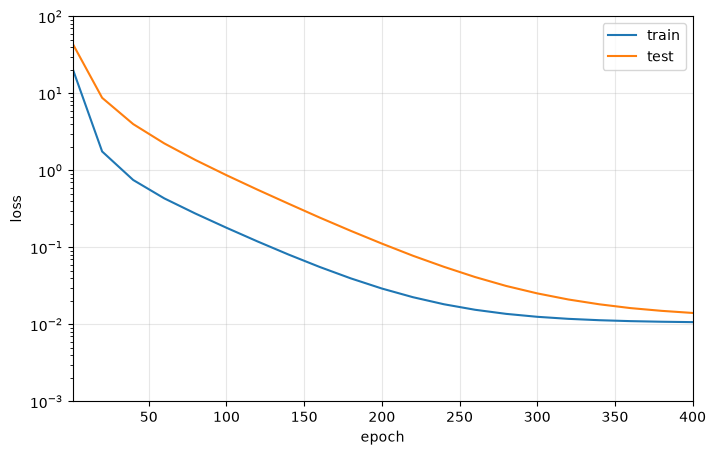

weight: [[ 5.0112495  1.2398386 -3.384569   5.5232   ]]


Sequential(
  (0): Linear(in_features=4, out_features=1, bias=False)
)

In [8]:
train(poly_features[:n_train,:4],poly_features[n_train:,:4],labels[:n_train],labels[n_train:])

线性函数拟合（欠拟合）

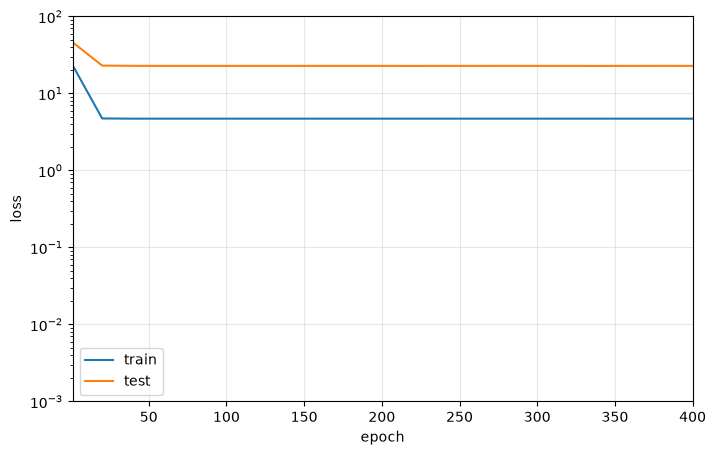

weight: [[3.8018398 3.362376 ]]


Sequential(
  (0): Linear(in_features=2, out_features=1, bias=False)
)

In [9]:
train(poly_features[:n_train,:2],poly_features[n_train:,:2],labels[:n_train],labels[n_train:])

高阶多项式拟合（过拟合）

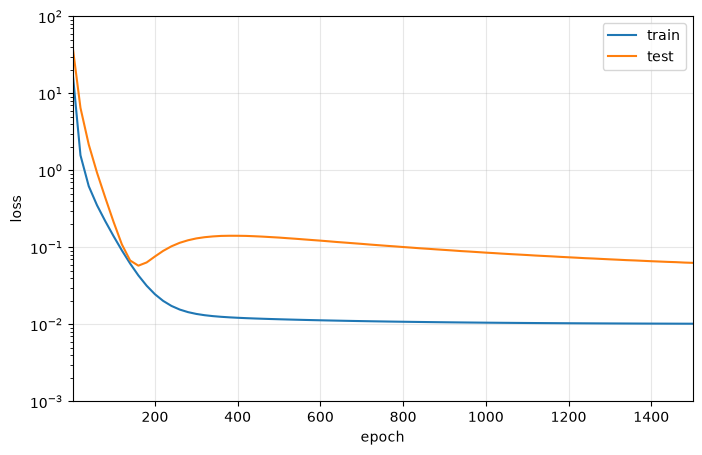

weight: [[ 5.009504    1.2750579  -3.3587518   5.1812487  -0.1800477   1.3392988
   0.31453204  0.05695894 -0.1816556   0.15918458 -0.06397361 -0.1730421
   0.09380063  0.19313386 -0.20469312  0.03436656  0.0215567  -0.00822015
   0.06853482 -0.17527418]]


Sequential(
  (0): Linear(in_features=20, out_features=1, bias=False)
)

In [10]:
train(poly_features[:n_train,:],poly_features[n_train:,:],labels[:n_train],labels[n_train:],num_epochs=1500)

小结：我们应当选择一个复杂度相当的模型来进行训练，虽然复杂度高的模型可以有效减小训练误差拟合训练数据集，但是泛化能力弱